In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
dataset_path = "../Dataset/Cleaned_Netflix_Dataset.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
# Check dataset information
print("Dataset Information:")
print("-" * 40)

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nRelease Year Range:")
print(df["release_year"].min(), "to", df["release_year"].max())

Dataset Information:
----------------------------------------
Total rows: 8790
Total columns: 10

Column Names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Data Types:
show_id         object
type            object
title           object
director        object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
dtype: object

Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Release Year Range:
1925 to 2021


In [4]:
# Count Netflix titles by release year
yearly_releases = (
    df.groupby("release_year")
      .size()
      .reset_index(name="total_titles")
      .sort_values("release_year")
)

print("Yearly Netflix Content Releases:")
display(yearly_releases)

Yearly Netflix Content Releases:


,release_year,total_titles
0,1925,1
1,1942,2
2,1943,3
3,1944,3
4,1945,4
...,...,...
69,2017,1030
70,2018,1146
71,2019,1030
72,2020,953


In [5]:
# Identify highest and lowest release years
highest_year = yearly_releases.loc[
    yearly_releases["total_titles"].idxmax()
]

lowest_year = yearly_releases.loc[
    yearly_releases["total_titles"].idxmin()
]

print("TREND ANALYSIS")
print("-" * 40)

print(
    f"Highest releases: {int(highest_year['release_year'])} "
    f"({int(highest_year['total_titles'])} titles)"
)

print(
    f"Lowest releases: {int(lowest_year['release_year'])} "
    f"({int(lowest_year['total_titles'])} titles)"
)

# Calculate year-over-year changes
yearly_releases["yearly_change"] = (
    yearly_releases["total_titles"].diff()
)

yearly_releases["percentage_change"] = (
    yearly_releases["total_titles"].pct_change() * 100
).round(2)

display(yearly_releases.tail(15))

TREND ANALYSIS
----------------------------------------
Highest releases: 2018 (1146 titles)
Lowest releases: 1925 (1 titles)


,release_year,total_titles,yearly_change,percentage_change
59,2007,88,-8.0,-8.33
60,2008,135,47.0,53.41
61,2009,152,17.0,12.59
62,2010,192,40.0,26.32
63,2011,185,-7.0,-3.65
64,2012,236,51.0,27.57
65,2013,286,50.0,21.19
66,2014,352,66.0,23.08
67,2015,555,203.0,57.67
68,2016,901,346.0,62.34


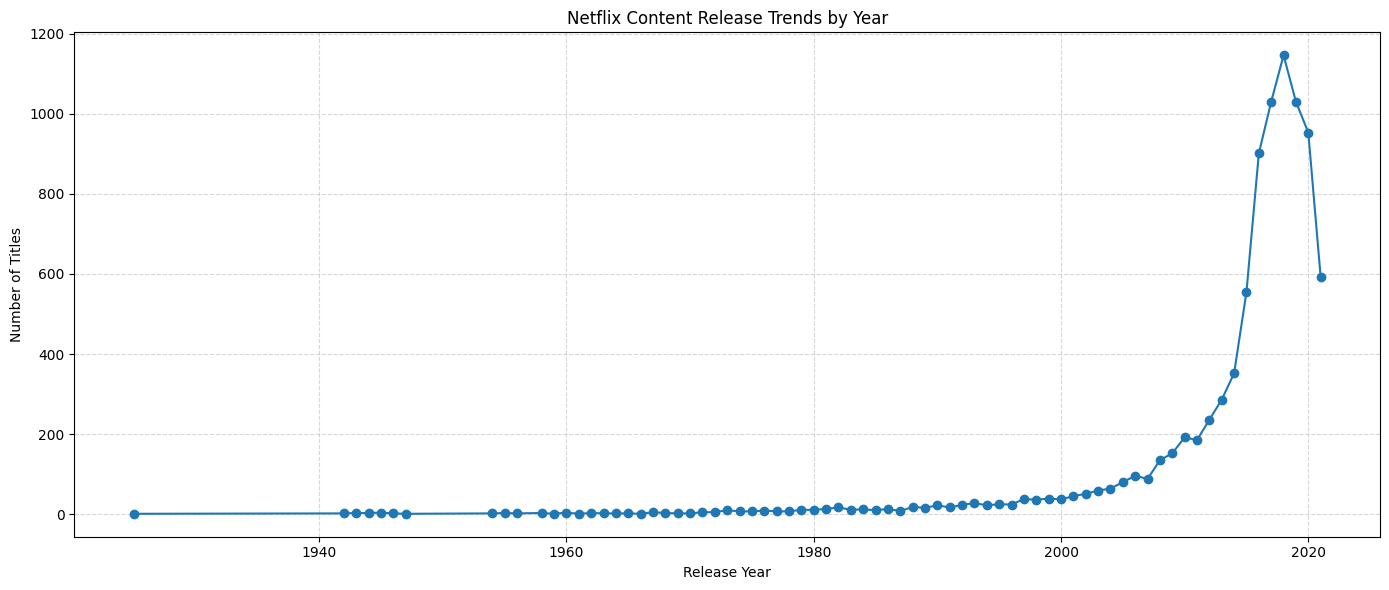

In [6]:
plt.figure(figsize=(14, 6))

plt.plot(
    yearly_releases["release_year"],
    yearly_releases["total_titles"],
    marker="o"
)

plt.title("Netflix Content Release Trends by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    "../Output/Netflix_Release_Year_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

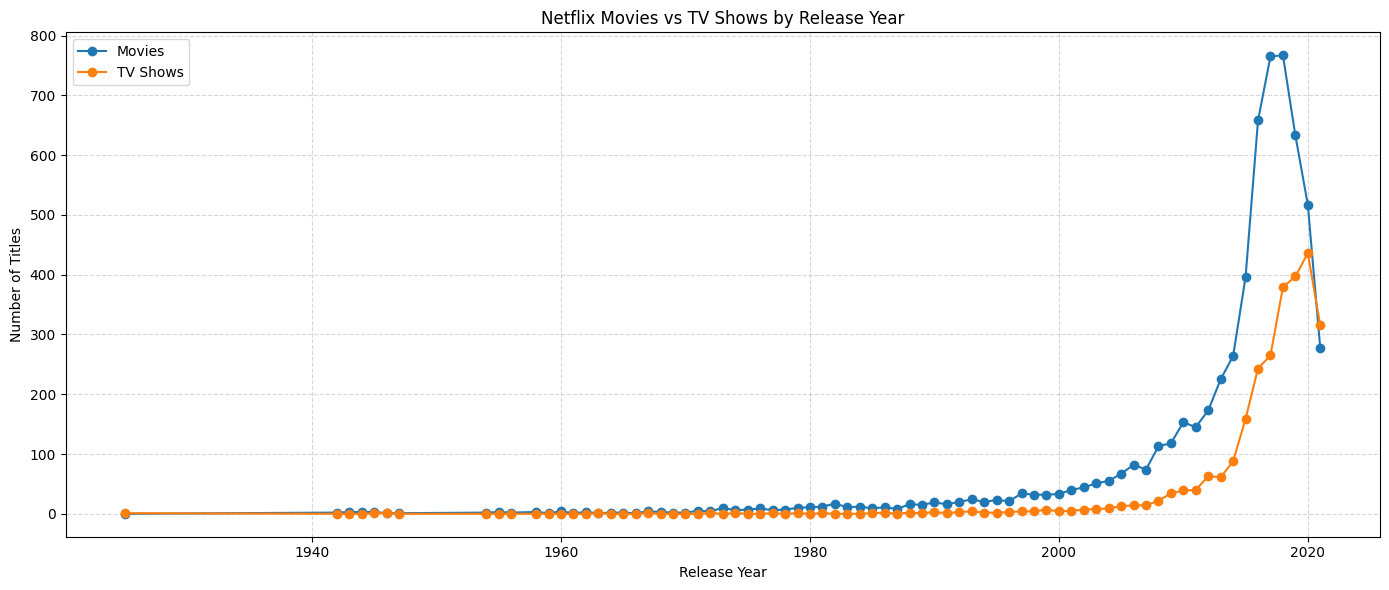

In [7]:
# Compare Movies and TV Shows by Release Year

content_by_year = (
    df.groupby(["release_year", "type"])
      .size()
      .unstack(fill_value=0)
)

plt.figure(figsize=(14, 6))

if "Movie" in content_by_year.columns:
    plt.plot(
        content_by_year.index,
        content_by_year["Movie"],
        marker="o",
        label="Movies"
    )

if "TV Show" in content_by_year.columns:
    plt.plot(
        content_by_year.index,
        content_by_year["TV Show"],
        marker="o",
        label="TV Shows"
    )

plt.title("Netflix Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    "../Output/Movies_vs_TV_Shows_by_Release_Year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Top 10 Release Years:


,release_year,total_titles
70,2018,1146
69,2017,1030
71,2019,1030
72,2020,953
68,2016,901
73,2021,592
67,2015,555
66,2014,352
65,2013,286
64,2012,236


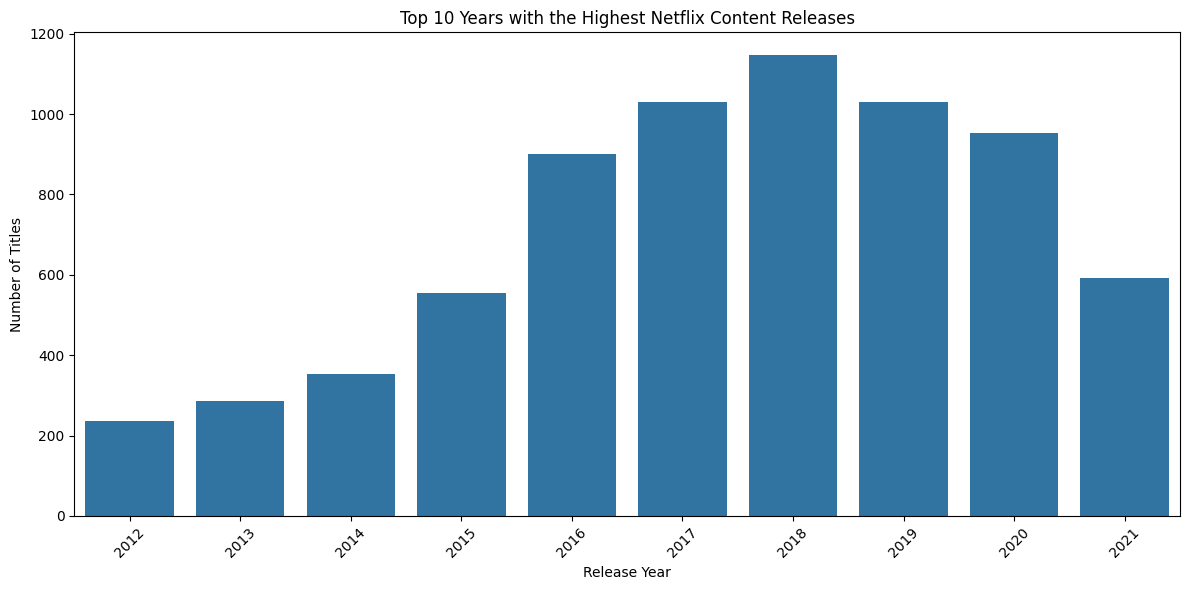

In [8]:
# Top 10 Years by Number of Netflix Titles

top_10_years = yearly_releases.nlargest(10, "total_titles")

print("Top 10 Release Years:")
display(
    top_10_years[
        ["release_year", "total_titles"]
    ].sort_values("total_titles", ascending=False)
)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_years,
    x="release_year",
    y="total_titles"
)

plt.title("Top 10 Years with the Highest Netflix Content Releases")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../Output/Top_10_Release_Years.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [9]:
# Final Business Insights

print("=" * 55)
print("NETFLIX RELEASE YEAR TREND ANALYSIS")
print("=" * 55)

total_titles = len(df)
total_years = df["release_year"].nunique()

highest_year = yearly_releases.loc[
    yearly_releases["total_titles"].idxmax()
]

movie_count = (df["type"] == "Movie").sum()
tv_count = (df["type"] == "TV Show").sum()

print(f"\nTotal Netflix titles analyzed: {total_titles}")
print(f"Different release years: {total_years}")

print(
    f"\nPeak release year: {int(highest_year['release_year'])}"
    f" ({int(highest_year['total_titles'])} titles)"
)

print(f"Total Movies: {movie_count}")
print(f"Total TV Shows: {tv_count}")

print("\nKEY BUSINESS INSIGHTS")
print("-" * 55)

print("1. Netflix titles are concentrated in recent release years.")
print("2. The highest number of titles was released in 2018.")
print("3. Movies account for more titles than TV Shows.")
print("4. Both Movies and TV Shows grew significantly in recent years.")
print("5. Lower counts in 2021 may reflect incomplete coverage in the dataset.")

print("\nCONCLUSION")
print("-" * 55)

print(
    "The analysis shows that Netflix content in the dataset is "
    "concentrated in recent release years, with 2018 recording "
    "the highest number of titles. Movies contribute more titles "
    "than TV Shows. These trends help summarize the release-year "
    "distribution of Netflix's available content."
)

NETFLIX RELEASE YEAR TREND ANALYSIS

Total Netflix titles analyzed: 8790
Different release years: 74

Peak release year: 2018 (1146 titles)
Total Movies: 6126
Total TV Shows: 2664

KEY BUSINESS INSIGHTS
-------------------------------------------------------
1. Netflix titles are concentrated in recent release years.
2. The highest number of titles was released in 2018.
3. Movies account for more titles than TV Shows.
4. Both Movies and TV Shows grew significantly in recent years.
5. Lower counts in 2021 may reflect incomplete coverage in the dataset.

CONCLUSION
-------------------------------------------------------
The analysis shows that Netflix content in the dataset is concentrated in recent release years, with 2018 recording the highest number of titles. Movies contribute more titles than TV Shows. These trends help summarize the release-year distribution of Netflix's available content.


In [10]:
# Save yearly trend analysis to CSV

yearly_releases.to_csv(
    "../Output/Netflix_Yearly_Trend_Analysis.csv",
    index=False
)

# Save the top 10 release years
top_10_years.to_csv(
    "../Output/Netflix_Top_10_Release_Years.csv",
    index=False
)

print("Analysis results saved successfully!")
print("1. Netflix_Yearly_Trend_Analysis.csv")
print("2. Netflix_Top_10_Release_Years.csv")

Analysis results saved successfully!
1. Netflix_Yearly_Trend_Analysis.csv
2. Netflix_Top_10_Release_Years.csv
